# Naive Bayes — Learn It Step by Step
**Contents**
1. Intuition and Bayes' theorem
2. Solving a small example by hand (Play Tennis)
3. The same example in code, from scratch, plus Laplace smoothing
4. Gaussian Naive Bayes for numeric features (from scratch, then sklearn)
5. Multinomial Naive Bayes for text (spam filter)
6. Summary: variants, pros and cons
7. Practice exercises

## 1. Intuition

Naive Bayes is a **probabilistic classifier**. For a new data point, it asks:

> *Given these features, which class is most probable?*

### Bayes' theorem
$$P(y \mid X) = \frac{P(X \mid y)\,P(y)}{P(X)}$$

| Term | Name | Meaning |
|---|---|---|
| $P(y)$ | Prior | How common the class is overall |
| $P(X \mid y)$ | Likelihood | How likely these features are if the class is $y$ |
| $P(X)$ | Evidence | The same for every class, so we can ignore it when comparing |
| $P(y \mid X)$ | Posterior | What we want |

### Why "naive"?
It assumes the features are **independent given the class**:
$$P(x_1, x_2, \dots, x_n \mid y) = P(x_1\mid y)\,P(x_2\mid y)\cdots P(x_n\mid y)$$

So the prediction rule becomes:
$$\hat y = \arg\max_y \; P(y)\prod_{i} P(x_i \mid y)$$

The assumption is rarely exactly true, but the classifier still works surprisingly well, especially for text.

## 2. Worked example by hand: Play Tennis

Question: **Outlook = Sunny, Temp = Cool**. Will they play?

In [1]:
import pandas as pd
import numpy as np

tennis = pd.DataFrame({
    'Outlook': ['Sunny','Sunny','Overcast','Rain','Rain','Rain','Overcast','Sunny','Sunny','Rain','Sunny','Overcast','Overcast','Rain'],
    'Temp':    ['Hot','Hot','Hot','Mild','Cool','Cool','Cool','Mild','Cool','Mild','Mild','Mild','Hot','Mild'],
    'Play':    ['No','No','Yes','Yes','Yes','No','Yes','No','Yes','Yes','Yes','Yes','Yes','No'],
})
tennis

,Outlook,Temp,Play
0,Sunny,Hot,No
1,Sunny,Hot,No
2,Overcast,Hot,Yes
3,Rain,Mild,Yes
4,Rain,Cool,Yes
5,Rain,Cool,No
6,Overcast,Cool,Yes
7,Sunny,Mild,No
8,Sunny,Cool,Yes
9,Rain,Mild,Yes


In [2]:
# frequency tables
print(pd.crosstab(tennis['Outlook'], tennis['Play']), '\n')
print(pd.crosstab(tennis['Temp'], tennis['Play']), '\n')
print(tennis['Play'].value_counts())

Play      No  Yes
Outlook          
Overcast   0    4
Rain       2    3
Sunny      3    2 

Play  No  Yes
Temp         
Cool   1    3
Hot    2    2
Mild   2    4 

Play
Yes    9
No     5
Name: count, dtype: int64


### Calculation by hand
Out of 14 days, Yes = 9 and No = 5.

**Priors**
- P(Yes) = 9/14, P(No) = 5/14

**Likelihoods** (read them from the tables above)
- P(Sunny | Yes) = 2/9, P(Sunny | No) = 3/5
- P(Cool | Yes) = 3/9, P(Cool | No) = 1/5

**Unnormalized posteriors**
- Yes: (9/14) × (2/9) × (3/9) = **0.0476**
- No: (5/14) × (3/5) × (1/5) = **0.0429**

**Normalize** (divide each by the sum)
- P(Yes | Sunny, Cool) = 0.0476 / (0.0476 + 0.0429) ≈ **0.526**
- P(No | Sunny, Cool) ≈ **0.474**

**Prediction: Yes** (just barely)

## 3. The same calculation in code, from scratch

In [3]:
def naive_bayes_categorical(df, target, query):
    scores = {}
    for c in df[target].unique():
        subset = df[df[target] == c]
        prob = len(subset) / len(df)                      # prior
        for feature, value in query.items():
            prob *= (subset[feature] == value).mean()     # likelihood
        scores[c] = prob
    total = sum(scores.values())
    return {c: round(s / total, 4) for c, s in scores.items()}, scores

posterior, raw = naive_bayes_categorical(tennis, 'Play', {'Outlook': 'Sunny', 'Temp': 'Cool'})
print('Raw scores :', {k: round(v, 4) for k, v in raw.items()})
print('Posterior  :', posterior)

Raw scores : {'No': np.float64(0.0429), 'Yes': np.float64(0.0476)}
Posterior  : {'No': np.float64(0.4737), 'Yes': np.float64(0.5263)}


### The zero-frequency problem
`Outlook = Overcast` **never** occurs with `No`, so P(Overcast | No) = 0. That zero makes the whole product for `No` equal 0, no matter what the other features say.

In [4]:
print(naive_bayes_categorical(tennis, 'Play', {'Outlook': 'Overcast', 'Temp': 'Cool'})[0])

{'No': np.float64(0.0), 'Yes': np.float64(1.0)}


**Fix: Laplace (additive) smoothing.** Add α (usually 1) to every count:
$$P(x_i = v \mid y) = \frac{\text{count}(v, y) + \alpha}{\text{count}(y) + \alpha \cdot k}$$
where $k$ is the number of distinct values of that feature.

In [5]:
def naive_bayes_smoothed(df, target, query, alpha=1):
    scores = {}
    for c in df[target].unique():
        subset = df[df[target] == c]
        prob = len(subset) / len(df)
        for feature, value in query.items():
            k = df[feature].nunique()
            prob *= ((subset[feature] == value).sum() + alpha) / (len(subset) + alpha * k)
        scores[c] = prob
    total = sum(scores.values())
    return {c: round(s / total, 4) for c, s in scores.items()}

print(naive_bayes_smoothed(tennis, 'Play', {'Outlook': 'Overcast', 'Temp': 'Cool'}))

{'No': np.float64(0.1111), 'Yes': np.float64(0.8889)}


## 4. Gaussian Naive Bayes for numeric features

You can't count how often "sepal length = 5.13" occurs. Instead, assume each feature follows a **normal distribution** within each class:
$$P(x_i \mid y) = \frac{1}{\sqrt{2\pi\sigma_y^2}} \exp\left(-\frac{(x_i-\mu_y)^2}{2\sigma_y^2}\right)$$

Training is simply: for each class, store the **mean** and **variance** of each feature.

In [6]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
pd.DataFrame(X, columns=iris.feature_names).assign(species=iris.target_names[y]).head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


### 4a. From scratch

In [7]:
class MyGaussianNB:
    def fit(self, X, y):
        self.classes = np.unique(y)
        self.mean  = np.array([X[y == c].mean(axis=0) for c in self.classes])
        self.var   = np.array([X[y == c].var(axis=0) + 1e-9 for c in self.classes])
        self.prior = np.array([(y == c).mean() for c in self.classes])
        return self

    def _log_likelihood(self, X):
        # log of the Gaussian pdf, summed over features (log turns products into sums)
        return np.array([
            -0.5 * np.sum(np.log(2 * np.pi * self.var[i]) + (X - self.mean[i])**2 / self.var[i], axis=1)
            for i in range(len(self.classes))
        ]).T

    def predict(self, X):
        log_post = self._log_likelihood(X) + np.log(self.prior)
        return self.classes[np.argmax(log_post, axis=1)]

my_nb = MyGaussianNB().fit(X_train, y_train)
my_pred = my_nb.predict(X_test)
print('From-scratch accuracy:', (my_pred == y_test).mean())

From-scratch accuracy: 0.9111111111111111


> **Why logs?** Multiplying many small probabilities underflows to 0 on a computer. Since $\log(ab) = \log a + \log b$ and log is increasing, the argmax doesn't change.

### 4b. With scikit-learn

sklearn accuracy: 0.9111111111111111
Same predictions as from-scratch? True
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45



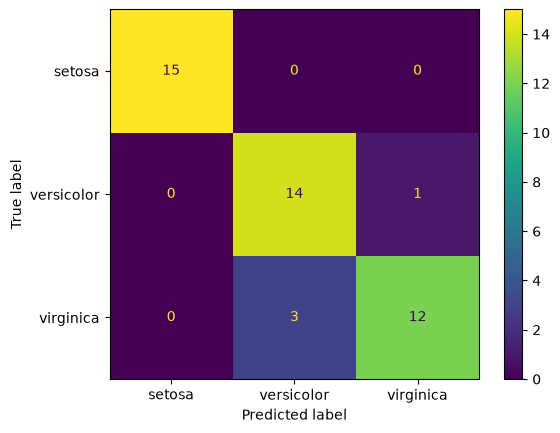

In [8]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

gnb = GaussianNB()
gnb.fit(X_train, y_train)
y_pred = gnb.predict(X_test)

print('sklearn accuracy:', accuracy_score(y_test, y_pred))
print('Same predictions as from-scratch?', (y_pred == my_pred).all())
print(classification_report(y_test, y_pred, target_names=iris.target_names))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=iris.target_names).plot()
plt.show()

In [9]:
# what the model learned
print('Class priors:', gnb.class_prior_)
pd.DataFrame(gnb.theta_, columns=iris.feature_names, index=iris.target_names).round(2)  # per-class means

Class priors: [0.33333333 0.33333333 0.33333333]


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
setosa,4.99,3.43,1.49,0.24
versicolor,5.95,2.73,4.24,1.31
virginica,6.68,3.01,5.63,2.07


In [10]:
# probabilities, not just labels
pd.DataFrame(gnb.predict_proba(X_test[:5]).round(3), columns=iris.target_names).assign(actual=iris.target_names[y_test[:5]])

,setosa,versicolor,virginica,actual
0,0.0,0.000,1.000,virginica
1,0.0,0.996,0.004,versicolor
2,0.0,0.847,0.153,virginica
3,0.0,0.668,0.332,versicolor
4,0.0,0.104,0.896,virginica


## 5. Multinomial Naive Bayes for text (spam filter)

For text, the features are **word counts**. MultinomialNB estimates P(word | class) from those counts. Text classification is where Naive Bayes is strongest.

In [11]:
messages = [
    ('Win a free iPhone now, click here', 'spam'),
    ('Congratulations you won a cash prize', 'spam'),
    ('Free entry to win money, claim now', 'spam'),
    ('Limited offer, buy cheap meds online', 'spam'),
    ('Urgent! Your account won a free reward', 'spam'),
    ('Claim your free gift card today', 'spam'),
    ('Cheap loans, click to apply now', 'spam'),
    ('You have been selected for a cash bonus', 'spam'),
    ('Are we still meeting for lunch tomorrow?', 'ham'),
    ('Can you send me the project report', 'ham'),
    ('Happy birthday! Have a great day', 'ham'),
    ('I will call you after the meeting', 'ham'),
    ('Please review the attached notes before class', 'ham'),
    ('Let us study for the exam this weekend', 'ham'),
    ('Mom asked if you are coming for dinner', 'ham'),
    ('The train is late, I will reach by 7', 'ham'),
]
texts, labels = zip(*messages)

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline

spam_model = make_pipeline(CountVectorizer(stop_words='english'), MultinomialNB(alpha=1.0))
spam_model.fit(texts, labels)

spam_col = list(spam_model.classes_).index('spam')
tests = ['Win free cash now', 'Are you coming to the meeting?', 'Claim your prize today', 'Send me the notes for the exam']
for t, p, pr in zip(tests, spam_model.predict(tests), spam_model.predict_proba(tests)):
    print(f'{p:>4}  P(spam)={pr[spam_col]:.2f}  <- {t}')

spam  P(spam)=0.97  <- Win free cash now
 ham  P(spam)=0.12  <- Are you coming to the meeting?
spam  P(spam)=0.89  <- Claim your prize today
 ham  P(spam)=0.08  <- Send me the notes for the exam


In [12]:
# which words push most toward spam?
vec, nb = spam_model.named_steps['countvectorizer'], spam_model.named_steps['multinomialnb']
ham_col = list(nb.classes_).index('ham')
log_ratio = nb.feature_log_prob_[spam_col] - nb.feature_log_prob_[ham_col]
pd.Series(log_ratio, index=vec.get_feature_names_out()).sort_values(ascending=False).head(10).round(2)

free               1.49
claim              0.98
cheap              0.98
cash               0.98
click              0.98
win                0.98
won                0.98
congratulations    0.57
entry              0.57
card               0.57
dtype: float64

## 6. Summary

### Which variant to use
| Variant | Feature type | Typical use |
|---|---|---|
| `GaussianNB` | Continuous numbers | Iris, sensor data |
| `MultinomialNB` | Counts (word frequencies) | Text classification, spam |
| `BernoulliNB` | Binary (word present / absent) | Short texts, yes/no features |
| `CategoricalNB` | Categories | Play Tennis-style data |
| `ComplementNB` | Counts, imbalanced classes | Imbalanced text data |

### Pros
- Very fast to train and predict (training is just counting and averaging)
- Works well with small data and with a very large number of features (text)
- Gives probabilities and is easy to interpret

### Cons
- Assumes the features are independent, so correlated features get "double counted"
- Its probabilities are often over-confident: useful for ranking, but not well calibrated
- GaussianNB assumes each feature is bell-shaped within each class
- Zero frequencies need smoothing (`alpha`)

### Key hyperparameters
- `alpha` (Multinomial/Bernoulli/Categorical): smoothing strength
- `var_smoothing` (Gaussian): adds a small amount of variance for numerical stability

## 7. Practice exercises
1. By hand: compute P(Play | Outlook=Rain, Temp=Hot), then check your answer with `naive_bayes_categorical`.
2. Use `CategoricalNB` from sklearn on the tennis data (hint: encode the values with `OrdinalEncoder`).
3. Swap `MultinomialNB` for `BernoulliNB` in the spam filter. Do the predictions change?
4. Try `alpha=0.01` and `alpha=10` in the spam model. What happens to the probabilities?
5. Compare `GaussianNB` with `LogisticRegression` on `load_breast_cancer()` using `cross_val_score`.